# 06 · Robustness sweep: 45 handheld captures (revision, Fig. *robustness*, *cond_\**)

The same label ("Vision Crack #1", code `lewb`) with five printed reference bars (0.55–2.75 mm), captured under
five conditions: **norm** (reference pose), **dist** (farther away), **roll** (in-plane rotation),
**pitch** and **yaw** (out-of-plane tilt).

Two independent views:
* **A. App gates.** The phone's corner detector and gates (notebook 02/03) run on each capture, with coverage relative to the norm label size.
* **B. Measurement chain** of the revision experiments (`visioncrack.sweep`): label coverage by area, barcode decode,
  barcode-derived scale and reference-bar error. These numbers feed the acceptance table (07), tilt model (08) and bias (09).

| | |
|---|---|
| **Inputs** | `data/raw/robustness/` (45 JPG + `metadata.csv`) |
| **Outputs** | `results/tables/robustness_per_capture.csv`; `results/figures/cond_{norm,dist,roll,pitch,yaw}.png`, `robustness_curves.png` |
| **Runtime** | ~30 s |

> **Folder names.** The capture folders were renamed after the original analysis. Old → current:
> `angle → roll` (in-plane rotation, measured ≈15°) and `roll → pitch` (out-of-plane tilt).
> `metadata.csv` keeps the old name in `legacy_name`. The three numbers in each file name
> (`pose_a/b/c`) are the phone's orientation sensor readings at capture time, **not** the label's pose.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [2]:
from visioncrack import sweep
res, ref = sweep.run_all()          # ~10 s for 45 captures
FOLDERS = sweep.FOLDERS
print('reference (norm) label box cx, cy, w, h =', np.round(ref.box, 1))
res.groupby('folder', sort=False).size().rename('captures').to_frame().T

reference (norm) label box cx, cy, w, h = [1509.  3129.   854.5  500.5]


folder,norm,dist,roll,pitch,yaw
captures,4,6,12,11,12


## A · App gates on every capture

In [3]:
from visioncrack import detection as det, gates
corners = {}
for r in res.itertuples():
    c = det.find_corners(sweep.label_crop(vc.read_rgb(r.path), r))
    corners[r.file] = None if c is None else c.as_array()
nq = [corners[f] for f in res[res.folder == 'norm'].file]
REF_W = np.mean([(abs(q[1, 0] - q[0, 0]) + abs(q[3, 0] - q[2, 0])) / 2 for q in nq])
REF_H = np.mean([(abs(q[2, 1] - q[0, 1]) + abs(q[3, 1] - q[1, 1])) / 2 for q in nq])
G = {f: gates.evaluate(q, REF_W, REF_H) for f, q in corners.items()}
res['app_result'] = [G[f].first_failure or 'accepted' for f in res.file]
res['app_min_ratio'] = [min(G[f].ratios.values()) if G[f].ratios else np.nan for f in res.file]
res['app_angle'] = [G[f].angle_deg for f in res.file]
print(f'norm label size: {REF_W:.0f} × {REF_H:.0f} px')
pd.crosstab(res.folder, res.app_result).reindex(FOLDERS)

norm label size: 839 × 483 px


app_result,accepted,corners,coverage
folder,,,
norm,4,0,0
dist,0,0,6
roll,0,0,12
pitch,2,6,3
yaw,0,0,12


**Note on pitch.** Two pitch captures (phone tilted ≈15°, `pose_c` ≈ 105) are **accepted** by the app gates, with coverage just at 0.95.
Six others lose a corner. Out-of-plane tilt is not reliably rejected (see notebook 03 §3 and 08).

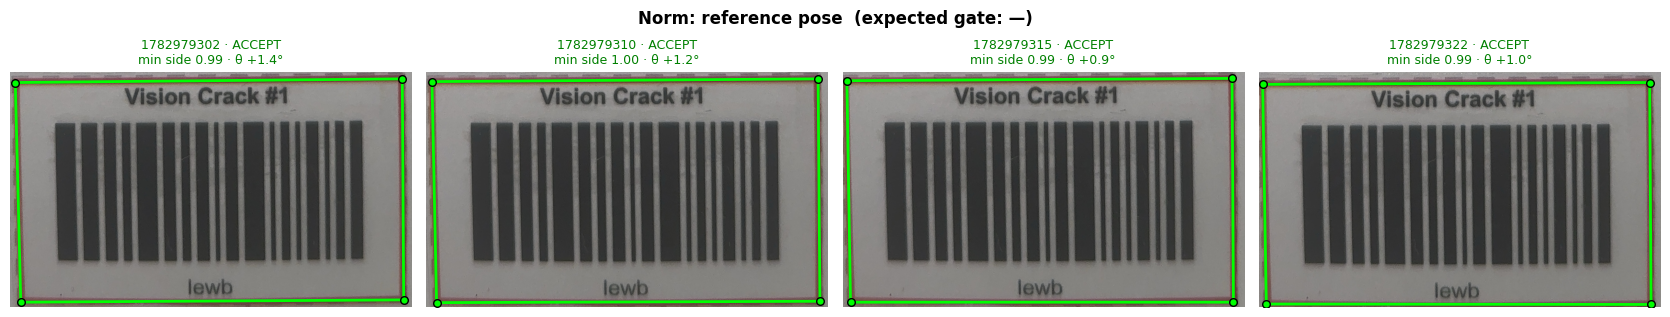

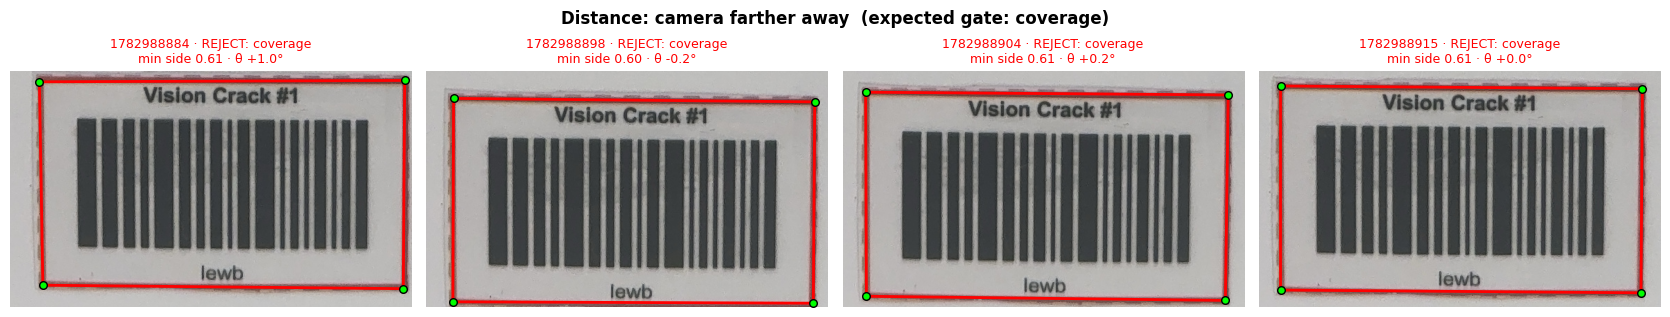

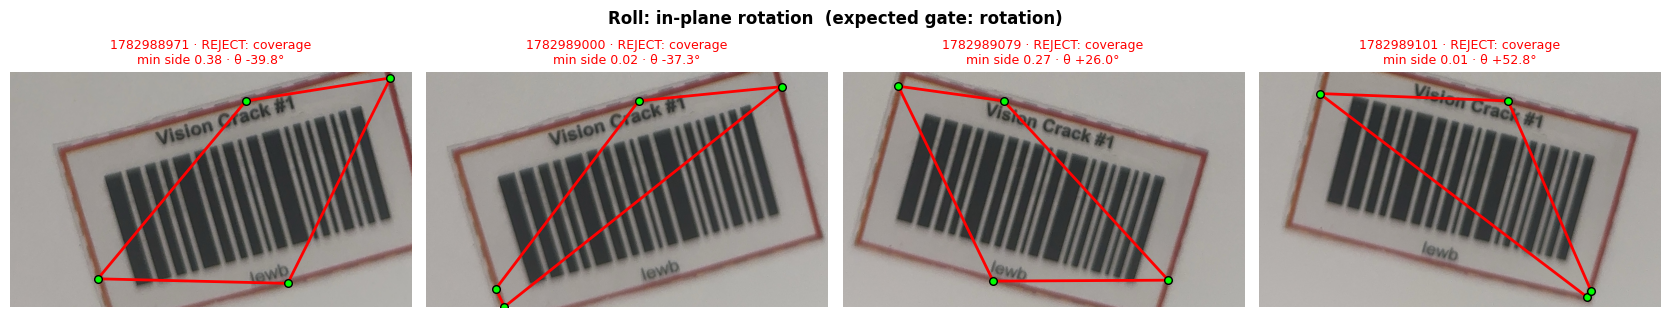

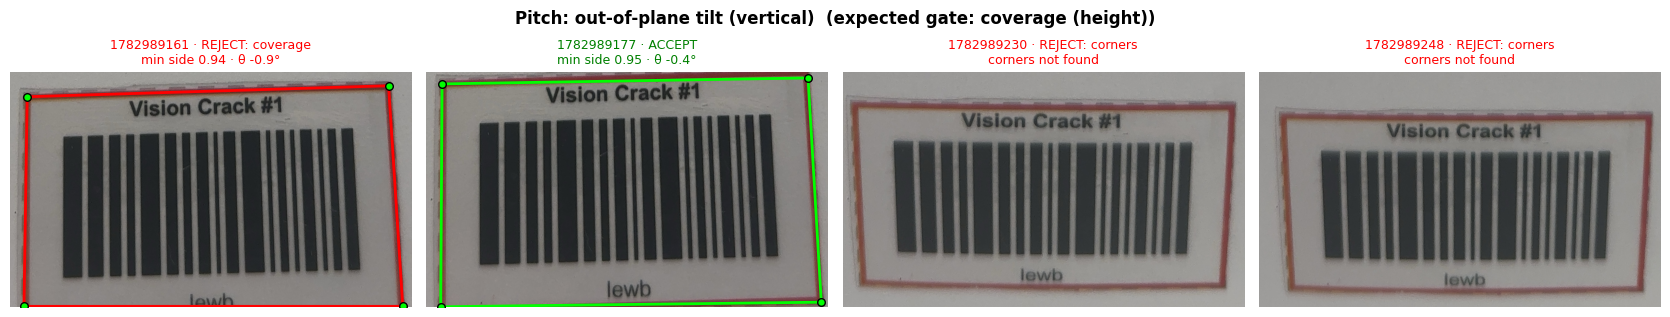

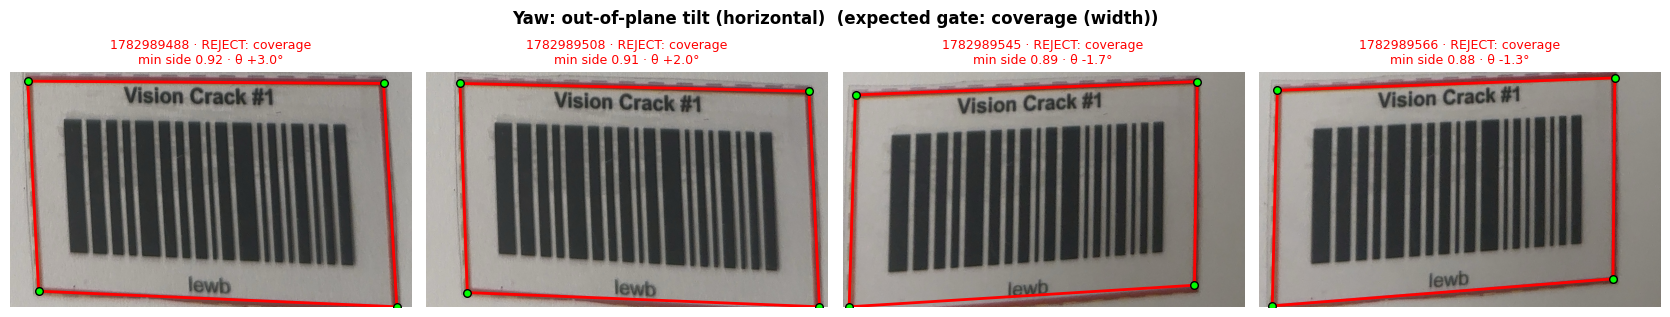

In [4]:
from matplotlib.patches import Polygon
def cond_figure(folder, n=4):
    sub = res[res.folder == folder]
    pick = sub.iloc[np.linspace(0, len(sub) - 1, min(n, len(sub))).round().astype(int)]
    name, what, gate = sweep.FOLDER_INFO[folder]
    fig, axes = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 3.4))
    for ax, r in zip(np.atleast_1d(axes), pick.itertuples()):
        crop = sweep.label_crop(vc.read_rgb(r.path), r); ax.imshow(crop); ax.axis('off')
        q, g = corners[r.file], G[r.file]
        if q is not None:
            ax.add_patch(Polygon(q[[0, 1, 3, 2]], closed=True, fill=False, ec='lime' if g.accepted else 'red', lw=2))
            ax.scatter(*q.T, s=30, c='lime', edgecolor='k', zorder=3)
        txt = 'ACCEPT' if g.accepted else f'REJECT: {g.first_failure}'
        sub_t = f'min side {r.app_min_ratio:.2f} · θ {r.app_angle:+.1f}°' if q is not None else 'corners not found'
        ax.set_title(f'{r.file[:10]} · {txt}\n{sub_t}', fontsize=9, color='green' if g.accepted else 'red')
    fig.suptitle(f'{name}: {what}  (expected gate: {gate})', weight='bold')
    plt.tight_layout(); plt.savefig(FIG / f'cond_{folder}.png', dpi=150); plt.show()

for f in FOLDERS:
    cond_figure(f)

## B · Measurement chain per condition

In [5]:
cols = ['coverage', 'coverage_ok', 'inplane_deg', 'decode_ok', 'scale', 'ref_found', 'ref_mae', 'valid_rows']
summary = res.groupby('folder', sort=False)[cols].mean().reindex(FOLDERS)
summary.round(4)

,coverage,coverage_ok,inplane_deg,decode_ok,scale,ref_found,ref_mae,valid_rows
folder,,,,,,,,
norm,1.0000,1.0000,0.4382,1.0,0.0518,1.0,0.0612,302.5
dist,0.3809,0.0000,0.4461,1.0,0.0787,1.0,0.0744,181.5
roll,0.6654,0.0000,15.0394,1.0,0.0589,1.0,0.1970,45.5
pitch,0.8816,0.4545,0.8719,1.0,0.0539,0.0,NaN,233.0
yaw,0.9258,0.2500,1.8102,0.5,0.0560,0.0,NaN,208.5


In [6]:
keep = ['folder', 'legacy_name', 'file', 'pose_a', 'pose_b', 'pose_c', 'coverage', 'inplane_deg', 'decoded',
        'decode_ok', 'scale', 'ref_mae', 'ref_mae_sub', 'valid_rows', 'app_result', 'app_min_ratio', 'app_angle']
res[keep].to_csv(TAB / 'robustness_per_capture.csv', index=False, float_format='%.5f')
# regression checks against the revision notebook outputs
assert round(res.decode_ok.mean(), 3) == 0.867
assert np.allclose(summary.loc[['norm', 'dist', 'roll'], 'ref_mae'].round(4), [0.0612, 0.0744, 0.1970])
print('✓ matches the revision-experiment outputs')

✓ matches the revision-experiment outputs


## Robustness curves
* **(A)** Coverage per condition.
* **(B)** Distance: reference-bar error with the **per-capture barcode scale** vs. one **fixed scale taken at norm**.
  The barcode makes the scale follow distance; a fixed scale does not.
* **(C)** Decode redundancy (rows that resolve all 18 bars) vs. coverage.
* **(D)** Error vs. in-plane rotation.

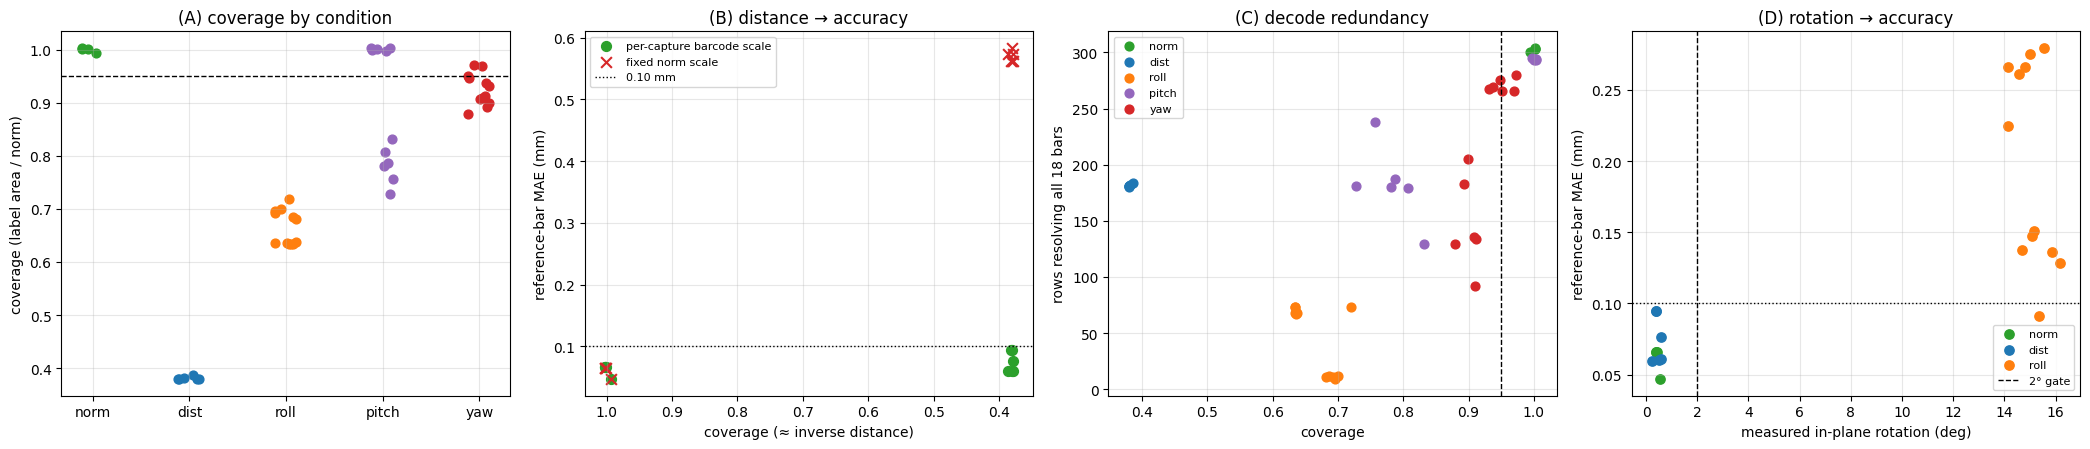

pitch and yaw captures have no resolvable reference bars with this chain → not in (B)/(D)


In [7]:
S_NORM = res[res.folder == 'norm'].scale.mean()
m = res.ref_found
res['ref_mae_fixed'] = np.nan
res.loc[m, 'ref_mae_fixed'] = [float(np.abs(mm / s * S_NORM - np.array(vc.ET_GT_MM)).mean())
                               for mm, s in zip(res[m].ref_mm, res[m].scale)]
C = dict(zip(FOLDERS, ['#2ca02c', '#1f77b4', '#ff7f0e', '#9467bd', '#d62728']))
fig, ax = plt.subplots(1, 4, figsize=(21, 4.6))
for i, f in enumerate(FOLDERS):
    g = res[res.folder == f]
    ax[0].scatter(np.full(len(g), i) + np.random.default_rng(0).uniform(-.12, .12, len(g)), g.coverage, c=C[f], s=40)
    ax[2].scatter(g.coverage, g.valid_rows, c=C[f], s=40, label=f)
ax[0].axhline(.95, color='k', ls='--', lw=1); ax[0].set_xticks(range(5), FOLDERS)
ax[0].set(ylabel='coverage (label area / norm)', title='(A) coverage by condition')
B = res[res.folder.isin(['norm', 'dist']) & m]
ax[1].scatter(B.coverage, B.ref_mae, c='#2ca02c', s=50, label='per-capture barcode scale')
ax[1].scatter(B.coverage, B.ref_mae_fixed, c='#d62728', marker='x', s=60, label='fixed norm scale')
ax[1].axhline(.1, color='k', ls=':', lw=1, label='0.10 mm'); ax[1].invert_xaxis()
ax[1].set(xlabel='coverage (≈ inverse distance)', ylabel='reference-bar MAE (mm)', title='(B) distance → accuracy'); ax[1].legend(fontsize=8)
ax[2].axvline(.95, color='k', ls='--', lw=1)
ax[2].set(xlabel='coverage', ylabel='rows resolving all 18 bars', title='(C) decode redundancy'); ax[2].legend(fontsize=8)
D = res[m]
for f in ['norm', 'dist', 'roll']:
    g = D[D.folder == f]; ax[3].scatter(g.inplane_deg, g.ref_mae, c=C[f], s=45, label=f)
ax[3].axvline(2, color='k', ls='--', lw=1, label='2° gate'); ax[3].axhline(.1, color='k', ls=':', lw=1)
ax[3].set(xlabel='measured in-plane rotation (deg)', ylabel='reference-bar MAE (mm)', title='(D) rotation → accuracy'); ax[3].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / 'robustness_curves.png', dpi=200); plt.show()
print('pitch and yaw captures have no resolvable reference bars with this chain → not in (B)/(D)')